In [1]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# 1. Carregar e juntar os CSVs limpos de todas as vacas
files = sorted(Path("./dados/clean").glob("*.csv"))

df = pd.concat(
    (pd.read_csv(f).assign(source_file=f.name) for f in files),
    ignore_index=True,
)

# 2. Definir as colunas de atributos (estatísticas do acelerômetro)
colunas_features = [
    "x_mean",
    "x_std",
    "x_min",
    "x_max",
    "y_mean",
    "y_std",
    "y_min",
    "y_max",
    "z_mean",
    "z_std",
    "z_min",
    "z_max",
    "mag_mean",
    "mag_std",
    "mag_min",
    "mag_max",
]

X = df[colunas_features]
y = df["behavior"]

# 3. Dividir em treino (70%) e teste (30%), mantendo a proporção de classes (estratificado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Conjunto de Treino: {X_train.shape[0]} janelas")
print(f"Conjunto de Teste: {X_test.shape[0]} janelas")

Conjunto de Treino: 49870 janelas
Conjunto de Teste: 21374 janelas


In [2]:
from sklearn.ensemble import RandomForestClassifier

# 1. Instanciar o modelo (class_weight balanced compensa o desbalanceamento das classes)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1,
)

# 2. Treinar o modelo com os dados de treino
print("Treinando o modelo Random Forest...")
rf_model.fit(X_train, y_train)
print("Modelo treinado com sucesso!")

Treinando o modelo Random Forest...


Modelo treinado com sucesso!


In [3]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Prever os comportamentos do conjunto de teste
y_pred = rf_model.predict(X_test)

# 2. Calcular a acurácia geral
acuracia = accuracy_score(y_test, y_pred)
print(f"Acurácia Geral do Modelo: {acuracia * 100:.2f}%\n")

# 3. Exibir precisão, recall e F1 por comportamento
print("Relatório de Classificação por Comportamento:")
print(classification_report(y_test, y_pred, zero_division=0))

Acurácia Geral do Modelo: 86.05%

Relatório de Classificação por Comportamento:
              precision    recall  f1-score   support

         2.0       0.77      0.79      0.78      6078
         3.0       0.83      0.80      0.81      4383
         7.0       0.92      0.93      0.93     10913

    accuracy                           0.86     21374
   macro avg       0.84      0.84      0.84     21374
weighted avg       0.86      0.86      0.86     21374



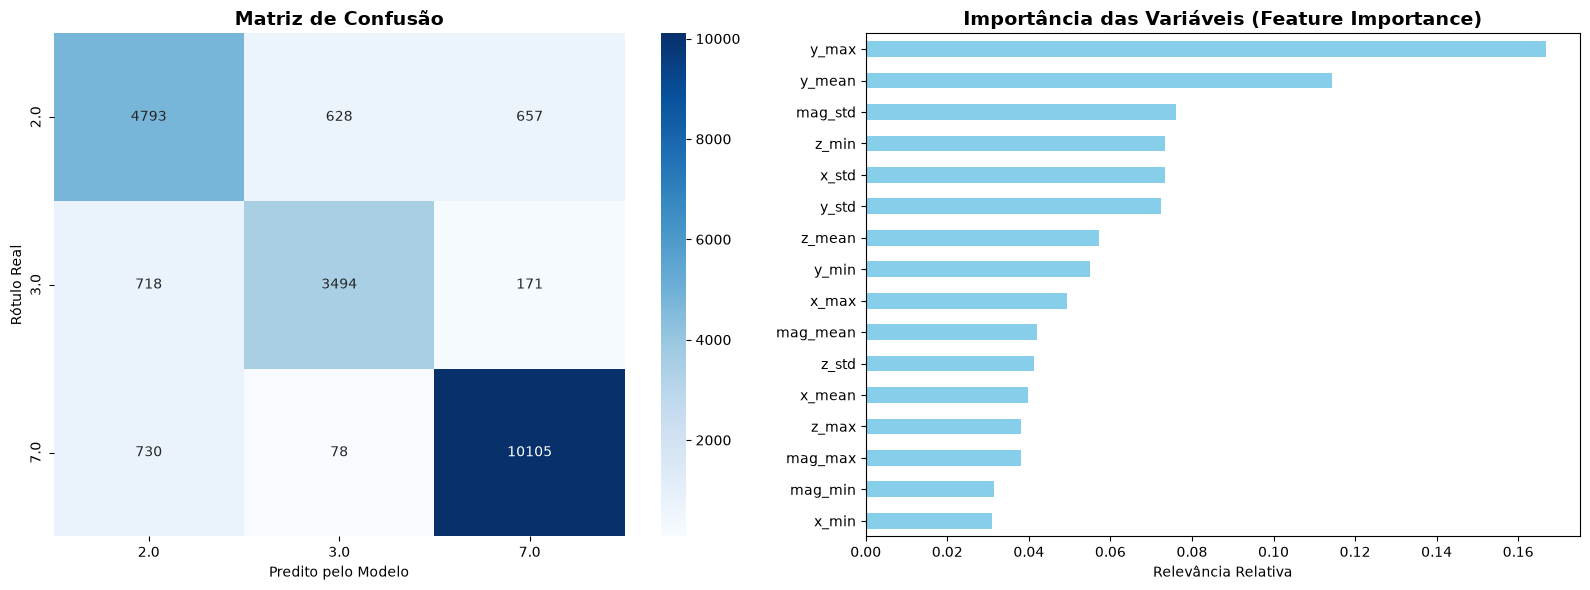

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Plotar a matriz de confusão
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_,
    ax=axes[0],
)
axes[0].set_title("Matriz de Confusão", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Predito pelo Modelo")
axes[0].set_ylabel("Rótulo Real")

# 2. Plotar a importância dos atributos
importancias = pd.Series(
    rf_model.feature_importances_, index=colunas_features
).sort_values(ascending=True)
importancias.plot(kind="barh", color="skyblue", ax=axes[1])
axes[1].set_title(
    "Importância das Variáveis (Feature Importance)", fontsize=14, fontweight="bold"
)
axes[1].set_xlabel("Relevância Relativa")

plt.tight_layout()
plt.show()

## Validação sem vazamento: leave-one-cow-out
A divisão aleatória acima coloca janelas vizinhas (10 s) da mesma vaca no treino e no teste, o que infla a acurácia.
Aqui cada vaca é testada por um modelo treinado nas outras 9, simulando uma vaca nunca vista.

In [5]:
from sklearn.metrics import accuracy_score, f1_score

# 1. Para cada vaca: treinar nas outras 9 e testar nela
resultados = []
for vaca in sorted(df["vaca_id"].unique()):
    treino, teste = df[df["vaca_id"] != vaca], df[df["vaca_id"] == vaca]
    modelo = RandomForestClassifier(
        n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1
    ).fit(treino[colunas_features], treino["behavior"])
    pred = modelo.predict(teste[colunas_features])
    resultados.append(
        {
            "vaca": vaca,
            "acuracia": accuracy_score(teste["behavior"], pred),
            "f1_macro": f1_score(teste["behavior"], pred, average="macro"),
        }
    )

# 2. Exibir o resultado por vaca e a média geral
loco = pd.DataFrame(resultados).set_index("vaca")
print(loco.round(3))
print(f"\nMédia: acurácia {loco['acuracia'].mean():.3f} | F1 macro {loco['f1_macro'].mean():.3f}")

      acuracia  f1_macro
vaca                    
T01      0.802     0.758
T02      0.769     0.743
T03      0.820     0.741
T04      0.850     0.834
T05      0.785     0.780
T06      0.619     0.615
T07      0.683     0.622
T08      0.774     0.747
T09      0.787     0.757
T10      0.843     0.821

Média: acurácia 0.773 | F1 macro 0.742
